# Final Project in CSAC 212 (Intro to AI)
Submitted by: <b>Lanuzo, Jessica Mae T. | BSCS-2A </b>
***
As part of the requirement for this course, each student is required to explore one or more topics discussed in this course and submit a report regarding it not less than 2 pages.

The Algorithm: **Logistic Regression**
> Logistic regression estimates the probability of an event occurring, such as voted or didn’t vote, based on a given data set of independent variables. (© IBM)

> It is used to describe data and to explain the relationship between one dependent binary variable and one or more nominal, ordinal, interval or ratio-level independent variables. (© Statistics Solutions 2024)

https://scikit-learn.org/1.5/modules/generated/sklearn.linear_model.LogisticRegression.html

The Dataset: **Reddit Text Dataset**

> A combination of two Kaggle datasets: "Depression: Reddit Dataset (Cleaned)" and "Reddit dataset: r/depression and r/SuicideWatch". The first dataset consists of 3900 instances each of texts labeled as "is_depression" and not, 'collected through web scrapping'. "is_ depression"-labeled texts were replaced with the first 3900 instances in the second dataset as they were specifically taken from the subreddits mentioned in its name, and therefore deemed to be more beneficial in training this model.

Dataset URL: https://www.kaggle.com/datasets/infamouscoder/depression-reddit-cleaned, 
https://www.kaggle.com/datasets/xavrig/reddit-dataset-rdepression-and-rsuicidewatch

***
### **Logistic Regression with Reddit Text Dataset**


#### 1.0 Importing libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix, accuracy_score, classification_report
plt.style.use('ggplot')
import re
import nltk
from nltk.corpus import stopwords

#### 1.1 Preparing the dataset

In [2]:
df = pd.read_csv("dataset.csv", delimiter=";")

In [3]:
print(df)

                                                   text  is_depressive
0     switchfoot http twitpic com y zl awww that s a...              0
1     is upset that he can t update his facebook by ...              0
2     kenichan i dived many time for the ball manage...              0
3          my whole body feel itchy and like it on fire              0
4     nationwideclass no it s not behaving at all i ...              0
...                                                 ...            ...
7795  So basically I know I am a bit insecure person...              1
7796  Just told my best friend that i beat depressio...              1
7797  This is my story.My first memory is from 4 yea...              1
7798  This was a while ago but I think about it ever...              1
7799  my whole life i have fantasized about the idea...              1

[7800 rows x 2 columns]


>Additional information about the dataset

In [4]:
print(df.info())
print()
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7800 entries, 0 to 7799
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   text           7800 non-null   object
 1   is_depressive  7800 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 122.0+ KB
None

       is_depressive
count    7800.000000
mean        0.500000
std         0.500032
min         0.000000
25%         0.000000
50%         0.500000
75%         1.000000
max         1.000000


#### 1.2 Pre-Processing the data



In [5]:
nltk.download("stopwords")
stop_words = set(stopwords.words("english"))

# removing special characters, numbers, stopwords and lowercasing text
def preprocess_text(text): 
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = text.lower()
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

df["text"] = df["text"].apply(preprocess_text)

print(df)


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Jessica\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


                                                   text  is_depressive
0     switchfoot http twitpic com zl awww bummer sho...              0
1     upset update facebook texting might cry result...              0
2     kenichan dived many time ball managed save res...              0
3                       whole body feel itchy like fire              0
4                      nationwideclass behaving mad see              0
...                                                 ...            ...
7795  basically know bit insecure person try best ne...              1
7796  told best friend beat depression knew depresse...              1
7797  storymy first memory years old woke apartment ...              1
7798  ago think every time struggling mom go support...              1
7799  whole life fantasized idea dying met death dar...              1

[7800 rows x 2 columns]


In [6]:
# Setting input (X) and output (y)
X = df["text"]
y = df["is_depressive"]

***
### Dataset Visualization

##### Wordcloud of all text data

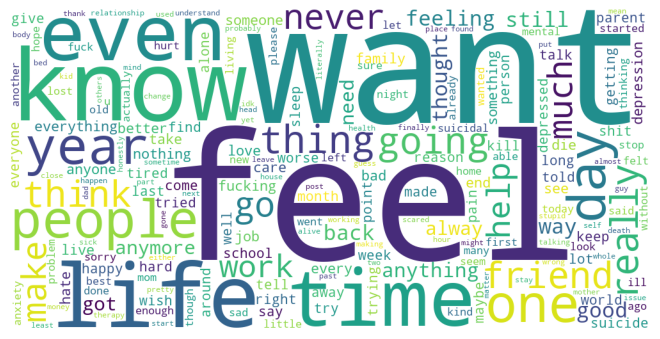

In [7]:
reddit_text = " ".join(rt for rt in df['text'])
wordcloud = WordCloud(width = 1000, height = 500,
                background_color ='white',
                min_font_size = 10,collocations=False).generate(reddit_text)

plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad = 0)
plt.show()

##### Wordcloud of Non-Depressive Reddit texts (0)

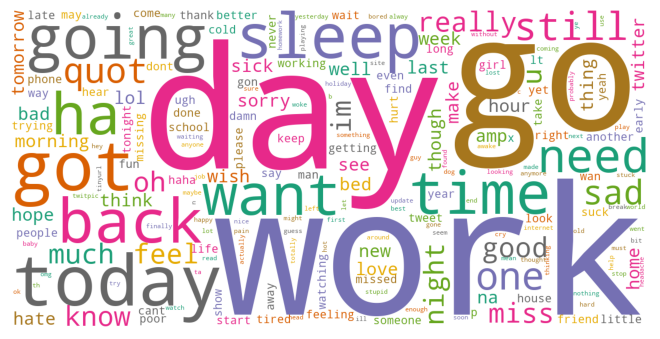

In [8]:
from wordcloud import WordCloud
reddit_text = " ".join([rt for rt in df.text[df.is_depressive==0]])
wordcloud = WordCloud(scale=3,
                      background_color='white',
                      colormap='Dark2',
                      collocations=False).generate(reddit_text)
                   
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad = 0)
plt.show()

##### Wordcloud of Depressive Reddit texts (0)

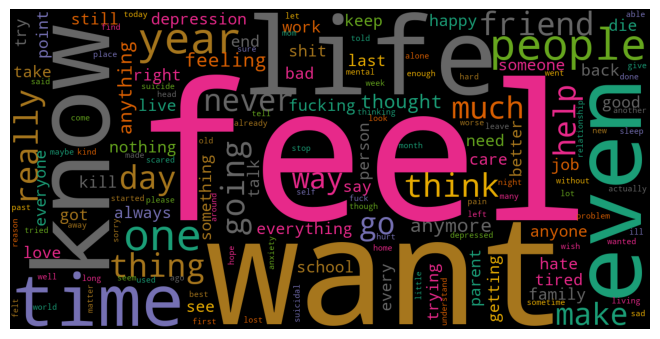

In [9]:
from wordcloud import WordCloud
reddit_text = " ".join([rt for rt in df.text[df.is_depressive==1]])
wordcloud = WordCloud(scale=3,
                      background_color='black',
                      max_words=150,
                      colormap='Dark2',
                      collocations=False).generate(reddit_text)
                   
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad = 0)
plt.show()

##### Distribution of Classes

C:\Users\Jessica\AppData\Local\Temp\ipykernel_16624\1893598270.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='is_depressive', data=df, palette='bright')


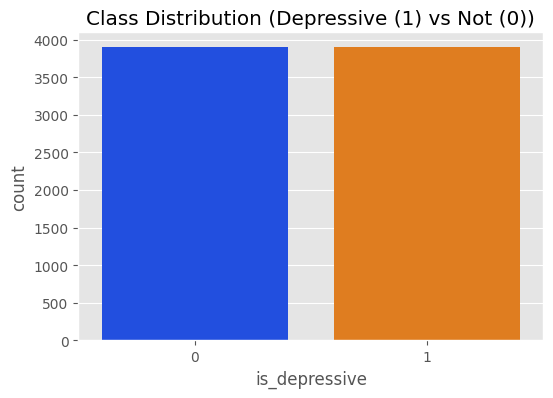

is_depressive
0    3900
1    3900
Name: count, dtype: int64


In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(x='is_depressive', data=df, palette='bright')
plt.title('Class Distribution (Depressive (1) vs Not (0))')
plt.show()

print(df["is_depressive"].value_counts())

***
### 

#### 1.3 Splitting the Dataset & Vectorizing Data

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
vectorizer = TfidfVectorizer(max_features=5000)
X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

#### 1.4 Building and Training the Model

In [13]:
model = LogisticRegression(C=.1, max_iter=500)
model.fit(X_train, y_train)

# Predict based on the test dataset
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))


Accuracy: 0.9358974358974359


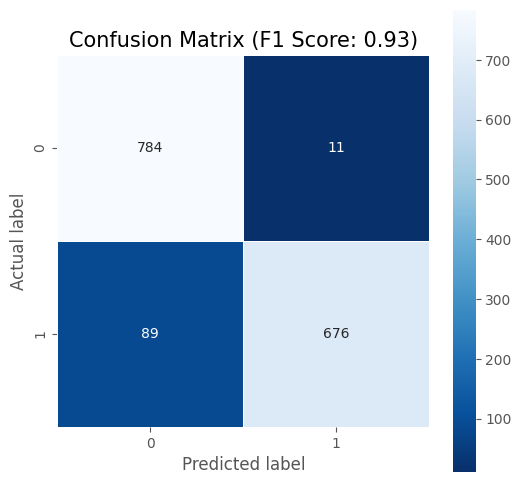

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.99      0.94       795
           1       0.98      0.88      0.93       765

    accuracy                           0.94      1560
   macro avg       0.94      0.93      0.94      1560
weighted avg       0.94      0.94      0.94      1560



In [14]:
# Generate a confusion matrix
cm = confusion_matrix(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square=True, cmap="Blues_r")
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
title = f'Confusion Matrix (F1 Score: {f1:.2f})'
plt.title(title, size=15)
plt.show()

print("Classification Report:\n", classification_report(y_test, y_pred))

The confusion matrix shows great model performance in addition to an F1 score of 0.93, but 100 instances were incorrectly labeled.

- **ACCURACY** (0.94): The model has pretty high accuracy, having been able to correctly predict 1460 labels out of 1560.
- **PRECISION** (0.94): There are only 11 false positives, showing good precision for label 1 (depressive text)
- **RECALL** (0.99, 0.88): Good recall for label 0. Recall for label 1 can still be improved. 

To improve the model's predictions, we can make some adjustments. 

#### 1.5 Tweaking the Model and Results

The Logistic Regression model consists of several parameters such as:
- **C** - Inverse of *regularization* strength (a method for increasing a model's generalizability—that is, it's ability to produce accurate predictions on new datasets); must be a positive float. Like in support vector machines, smaller values specify stronger regularization.
- **solver** - Algorithm to use in the optimization problem. Default is ‘lbfgs’. For small datasets, ‘liblinear’ is a good choice, whereas ‘sag’ and ‘saga’ are faster for large ones; ‘liblinear’ and ‘newton-cholesky’ can only handle binary classification by default. 
- **max_iter** - Maximum number of iterations taken for the solvers to converge.

`False positive/negative concerns` are usually addressed by manipulating the decision threshold (regularization) and class weights which we did here.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import joblib

model = LogisticRegression(C=15, random_state=42, class_weight={0: 1, 1: 2})
# C set to 15, class 1's weight is adjusted to be heavier than class 0
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Save the model and vectorizer to a file
joblib.dump(vectorizer, 'vectorizer.pkl')
joblib.dump(model, 'logistic_regression_model.pkl')
print("Model saved successfully!")

print("Accuracy:", accuracy_score(y_test, y_pred))

Model saved successfully!
Accuracy: 0.9724358974358974


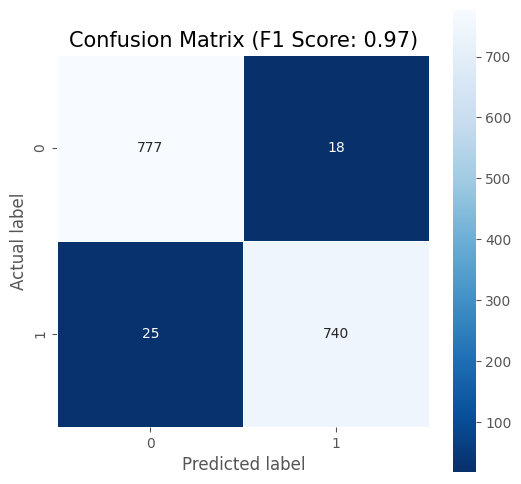

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.98      0.97       795
           1       0.98      0.97      0.97       765

    accuracy                           0.97      1560
   macro avg       0.97      0.97      0.97      1560
weighted avg       0.97      0.97      0.97      1560



In [16]:
# Generate a confusion matrix
cm = confusion_matrix(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square=True, cmap="Blues_r")
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
title = f'Confusion Matrix (F1 Score: {f1:.2f})'
plt.title(title, size=15)
plt.show()

print("Classification Report:\n", classification_report(y_test, y_pred))

Raising the `C` from 0.1 to 15, which weakened the regularization, and adjusting the class weights raised the model's F1 score to 0.97 as well as its other metric values--the accuracy and precision now both at 0.97. The recall for class 0 decreased by .01 but the improvement for class 1's recall (the priority of this model) outweights that loss.  

***
### **Using the Trained Model for Text Classification**

In [17]:
loaded_pipeline = joblib.load('logistic_regression_model.pkl')
vectorizer = joblib.load('vectorizer.pkl')

text = ["Everything just feels so wrong", 
        "Yo, I saw a cat. I want it.", 
        "I want to end it",
        "Why am i like this"
]
text = vectorizer.transform(text)

y_pred = loaded_pipeline.predict(text)

print("Predictions:", y_pred)

Predictions: [1 0 1 0]


In [18]:
loaded_pipeline = joblib.load('logistic_regression_model.pkl')
vectorizer = joblib.load('vectorizer.pkl')

text = ["i guess i was never enough for her. i did everything i could. I showed her how much i cared, tried to make her smile, and hoped she’d notice me the way i noticed her. but in the end, it didn’t matter. she left, transferred to another school, and now she likes someone else. i don’t even think she remembers me, and it hurts to know i was just... invisible to her. it’s like all the effort i gave meant nothing. i feel like i was chasing something that was never mine to begin with"
]
text = vectorizer.transform(text)

y_pred = loaded_pipeline.predict(text)

print("Predictions:", y_pred)

Predictions: [1]


***
### **Building a Neural Network (for metrics comparison)**

#### 2.0 Importing libraries

In [31]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, Embedding, LSTM
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from keras.models import Sequential
from keras.callbacks import EarlyStopping
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

#### 2.1 Loading and Pre-Processing the Dataset

In [36]:
data = pd.read_csv("dataset.csv", delimiter=';')

# data.drop_duplicates(subset=['text'],keep='first',inplace=True)
X = data["text"]
y = data["is_depressive"]

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [37]:
# Vectorize the text data
vectorizer = CountVectorizer()

tokenizer = Tokenizer(num_words=10000)
tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
test_sequences = tokenizer.texts_to_sequences(X_test)

max_length = 100
X_train = pad_sequences(train_sequences, maxlen=max_length)
X_test = pad_sequences(test_sequences, maxlen=max_length)

y_train = np.array(y_train)
y_test = np.array(y_test)

#### 2.2 Building and Training the Neural Network

In [38]:
input_shape = X_train.shape[1]

model = Sequential()
model.add(Embedding(input_dim=10000, output_dim=64, input_length=input_shape))
model.add(LSTM(32))
model.add(Dense(1, activation='sigmoid'))

early_stopping_loss = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
early_stopping_accuracy = EarlyStopping(monitor='val_accuracy', patience=2, restore_best_weights=True)


model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.fit(X_train, y_train, epochs=10, batch_size=64, validation_data=(X_test, y_test), callbacks=[early_stopping_loss, early_stopping_accuracy])
y_pred = (model.predict(X_test) > 0.5).astype(int)

Epoch 1/10


c:\Users\Jessica\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


98/98 ━━━━━━━━━━━━━━━━━━━━ 8s 47ms/step - accuracy: 0.9097 - loss: 0.4147 - val_accuracy: 0.9641 - val_loss: 0.1183
Epoch 2/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.9682 - loss: 0.0979 - val_accuracy: 0.9808 - val_loss: 0.0665
Epoch 3/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.9872 - loss: 0.0461 - val_accuracy: 0.9859 - val_loss: 0.0500
Epoch 4/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.9908 - loss: 0.0276 - val_accuracy: 0.9853 - val_loss: 0.0495
Epoch 5/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.9943 - loss: 0.0188 - val_accuracy: 0.9859 - val_loss: 0.0447
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


#### 2.3 Results

In [39]:
score = model.evaluate(X_test, y_test,verbose=1)
print(score)

49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9873 - loss: 0.0440
[0.05001392960548401, 0.985897421836853]


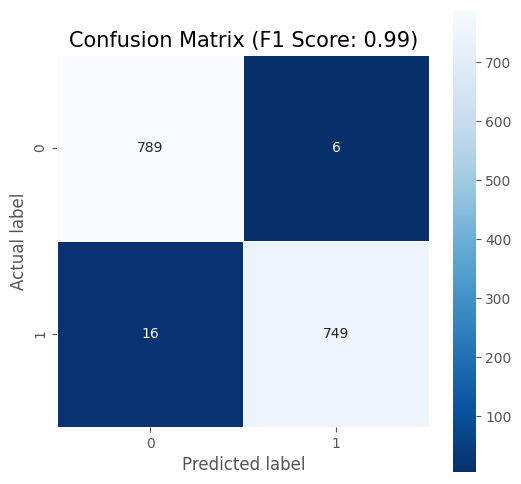

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       795
           1       0.99      0.98      0.99       765

    accuracy                           0.99      1560
   macro avg       0.99      0.99      0.99      1560
weighted avg       0.99      0.99      0.99      1560



In [40]:
# Generate a confusion matrix
cm = confusion_matrix(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square=True, cmap="Blues_r")
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
title = f'Confusion Matrix (F1 Score: {f1:.2f})'
plt.title(title, size=15)
plt.show()

print(classification_report(y_test, y_pred))

Higher (0.02) metrics than Logistic Regression Model even with just a simple framework. Still, the Logistic Regression model did well for a Machine Learning classifier.